# Exploratory Data Analysis (EDA)

## 1. Setup

### 1.1 Imports

In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import holidays
import ast

from haversine import haversine
from math import radians, sin, cos, sqrt, atan2

### 1.2 Helper Functions

In [33]:
def compute_distance(polyline) -> float:
    """
    Compute the total distance along a polyline in kilometers.

    Args:
        polyline: A sequence of [longitude, latitude] coordinate points.

    Returns:
        float: The total distance along the polyline. Returns 0 if the
        polyline contains fewer than two points.
    """
    if len(polyline) < 2:
        return 0

    distance = 0
    for i in range(len(polyline) - 1):
        distance += haversine(polyline[i], polyline[i + 1])

    return distance

def haversine(p1, p2) -> float:
    """
    Calculate the great-circle distance between two [longitude, latitude] points.

    Returns:
        float: Distance between the two points in kilometers.
    """
    lon1, lat1 = p1
    lon2, lat2 = p2

    R = 6371

    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)

    a = (
        sin(dlat / 2) ** 2
        + cos(radians(lat1))
        * cos(radians(lat2))
        * sin(dlon / 2) ** 2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

def is_within_city_bounds(polyline) -> bool:
    """
    Check whether all points in a parsed polyline are within the city bounds.
    """
    if not polyline:
        return False

    return all(
        CITY_BOUNDS[0] <= lon <= CITY_BOUNDS[1]
        and CITY_BOUNDS[2] <= lat <= CITY_BOUNDS[3]
        for lon, lat in polyline
    )

def has_large_jump(polyline, max_jump_km=1.0) -> bool:
    """
    Detect consecutive GPS points farther apart than max_jump_km.

    The polyline must contain parsed [longitude, latitude] points.
    """
    if len(polyline) < 2:
        return False

    for i in range(len(polyline) - 1):
        dist = haversine(polyline[i], polyline[i + 1])
        if dist > max_jump_km:
            return True

    return False

def get_correct_day_type(date, holiday_dates, day_before_holiday) -> str:
    """
    Determine the correct day type for a given date.
    
    Args:
        date (datetime.date): The date to check.
        holiday_dates (set): A set of holiday dates.
        day_before_holiday (set): A set of dates that are the day before holidays.
    Returns:
        str: "A" for normal days, "B" for holidays, "C" for days before holidays.
    """
    
    if date in holiday_dates:
        return "B"
    elif date in day_before_holiday:
        return "C"
    else:
        return "A"

### 1.3 Constants

In [42]:
DATA_PATH = "../src/data/porto.csv"

SUBSET_SIZE = 15000

PORTO_CENTER = [-8.6291, 41.1579]       # Porto city center: [longitude, latitude]
MAIN_STATION = [-8.610454, 41.145557]   # Porto Campanhã: [longitude, latitude]
AIRPORT = [-8.670828, 41.236818]        # Francisco Sá Carneiro Airport: [longitude, latitude]

CITY_BOUNDS = (-8.65, -8.55, 41.13, 41.18)

### 1.3 Load Dataset

In [13]:
df = pd.read_csv(DATA_PATH)

## 2. Dataset Overview

In [31]:
print("Shape:", df.shape)
print("Number of taxi drivers:", df['TAXI_ID'].nunique())

Shape: (1710670, 9)


In [32]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str),
    "Non-null values": df.notna().sum(),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})

display(column_info)

,Column,Data type,Non-null values,Missing values,Unique values
TRIP_ID,TRIP_ID,int64,1710670,0,1710589
CALL_TYPE,CALL_TYPE,str,1710670,0,3
ORIGIN_CALL,ORIGIN_CALL,float64,364770,1345900,57105
ORIGIN_STAND,ORIGIN_STAND,float64,806579,904091,63
TAXI_ID,TAXI_ID,int64,1710670,0,448
TIMESTAMP,TIMESTAMP,int64,1710670,0,1655366
DAY_TYPE,DAY_TYPE,str,1710670,0,1
MISSING_DATA,MISSING_DATA,bool,1710670,0,2
POLYLINE,POLYLINE,str,1710670,0,1703650


In [33]:
display(df.head())

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
0,1372636858620000589,C,NaN,NaN,20000589,1372636858,A,False,"[[-8.618643,41.141412],[-8.618499,41.141376],[..."
1,1372637303620000596,B,NaN,7.0,20000596,1372637303,A,False,"[[-8.639847,41.159826],[-8.640351,41.159871],[..."
2,1372636951620000320,C,NaN,NaN,20000320,1372636951,A,False,"[[-8.612964,41.140359],[-8.613378,41.14035],[-..."
3,1372636854620000520,C,NaN,NaN,20000520,1372636854,A,False,"[[-8.574678,41.151951],[-8.574705,41.151942],[..."
4,1372637091620000337,C,NaN,NaN,20000337,1372637091,A,False,"[[-8.645994,41.18049],[-8.645949,41.180517],[-..."


In [34]:
display(df.describe(include="all"))

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
count,1.710670e+06,1710670,364770.000000,806579.000000,1.710670e+06,1.710670e+06,1710670,1710670,1710670
unique,NaN,3,NaN,NaN,NaN,NaN,1,2,1703650
top,NaN,B,NaN,NaN,NaN,NaN,A,False,[]
freq,NaN,817881,NaN,NaN,NaN,NaN,1710670,1710660,5901
mean,1.388622e+18,NaN,24490.363018,30.272381,2.000035e+07,1.388622e+09,NaN,NaN,NaN
std,9.180944e+15,NaN,19624.290043,17.747840,2.112405e+02,9.180944e+06,NaN,NaN,NaN
min,1.372637e+18,NaN,2001.000000,1.000000,2.000000e+07,1.372637e+09,NaN,NaN,NaN
25%,1.380731e+18,NaN,6593.000000,15.000000,2.000017e+07,1.380731e+09,NaN,NaN,NaN
50%,1.388493e+18,NaN,18755.000000,27.000000,2.000034e+07,1.388493e+09,NaN,NaN,NaN
75%,1.396750e+18,NaN,40808.000000,49.000000,2.000052e+07,1.396750e+09,NaN,NaN,NaN


## 2. Data Preparation

In [14]:
df["DATETIME"] = pd.to_datetime(df["TIMESTAMP"], unit="s", utc=True).dt.tz_convert("Europe/Lisbon")
df["DATE"] = df["DATETIME"].dt.date
df["POLYLINE"] = df["POLYLINE"].apply(ast.literal_eval)
df["GPS_POINTS"] = df["POLYLINE"].apply(len)
df["DURATION"] = (df["GPS_POINTS"] - 1) * 15
df["DISTANCE"] = df["POLYLINE"].apply(compute_distance)

## 3. Distribution of Call Types

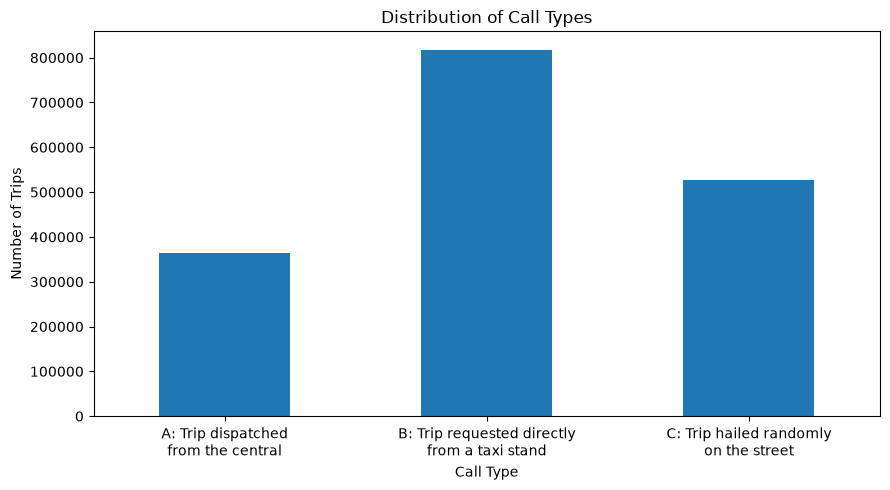

In [15]:
call_type_names = {
    "A": "A: Trip dispatched\nfrom the central",
    "B": "B: Trip requested directly\nfrom a taxi stand",
    "C": "C: Trip hailed randomly\non the street"
}

call_type_counts = (
    df["CALL_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

call_type_counts.index = call_type_counts.index.map(call_type_names)

ax = call_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Call Types",
    xlabel="Call Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("../src/results/call_type_distribution.png", bbox_inches="tight")
plt.show()

## 4. Distribution of Day Types

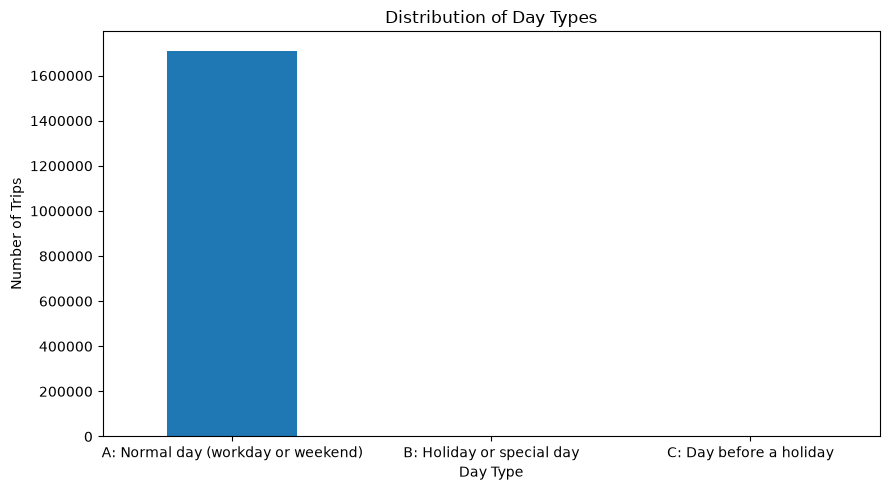

In [16]:
day_type_names = {
    "A": "A: Normal day (workday or weekend)",
    "B": "B: Holiday or special day",
    "C": "C: Day before a holiday"
}

day_type_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

day_type_counts.index = day_type_counts.index.map(day_type_names)

ax = day_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("../src/results/day_type_distribution.png", bbox_inches="tight")
plt.show()

## 5. Distribution of Trips at Different Times

### 5.1 Number of Trips per Hour

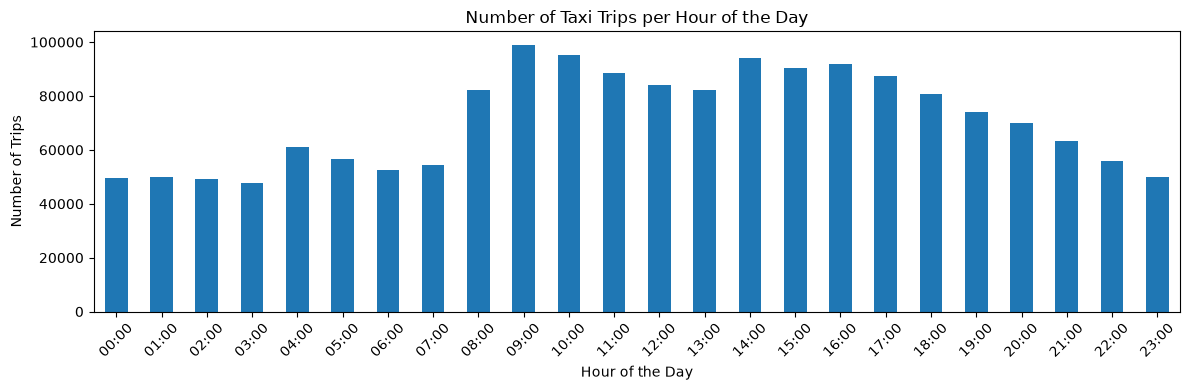

In [17]:
trips_per_hour = (
    df.groupby(df["DATETIME"].dt.hour)
      .size()
      .reindex(range(24), fill_value=0)
)

ax = trips_per_hour.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Hour of the Day",
    xlabel="Hour of the Day",
    ylabel="Number of Trips"
)

ax.set_xticklabels(
    [f"{hour:02d}:00" for hour in range(24)],
    rotation=45
)
plt.tight_layout()
plt.savefig("../src/results/number_of_taxi_trips_per_hour.png", bbox_inches="tight")
plt.show()

### 5.2 Number of Trips per Weekday

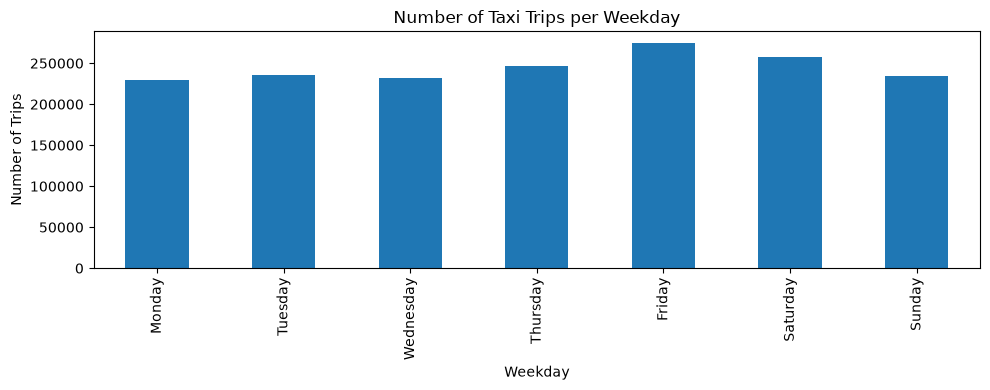

In [18]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

trips_per_weekday = (
    df.groupby(df["DATETIME"].dt.day_name())
      .size()
      .reindex(weekday_order)
)

trips_per_weekday.plot(
    kind="bar",
    figsize=(10, 4),
    title="Number of Taxi Trips per Weekday",
    xlabel="Weekday",
    ylabel="Number of Trips"
)
plt.tight_layout()
plt.savefig("../src/results/number_of_taxi_trips_per_day.png", bbox_inches="tight")
plt.show()

### 5.3 Number of Trips per Month

/var/folders/v9/fklyrqjn7_qd4_zsqzbjx5zc0000gn/T/ipykernel_88631/940373525.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df.groupby(df["DATETIME"].dt.to_period("M"))


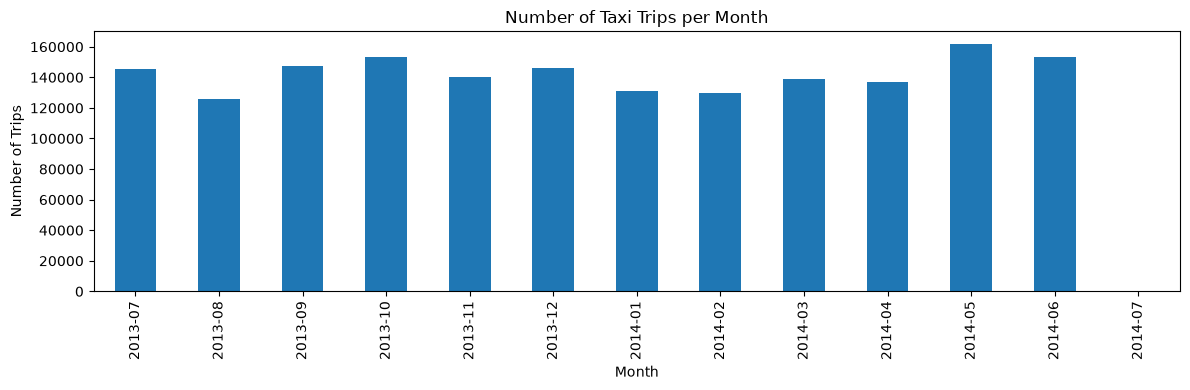

In [19]:
trips_per_month = (
    df.groupby(df["DATETIME"].dt.to_period("M"))
      .size()
      .sort_index()
)

trips_per_month.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Month",
    xlabel="Month",
    ylabel="Number of Trips"
)
plt.tight_layout()
plt.savefig("../src/results/number_of_taxi_trips_per_month.png", bbox_inches="tight")
plt.show()

## 6. Distribution of GPS Points per Trip

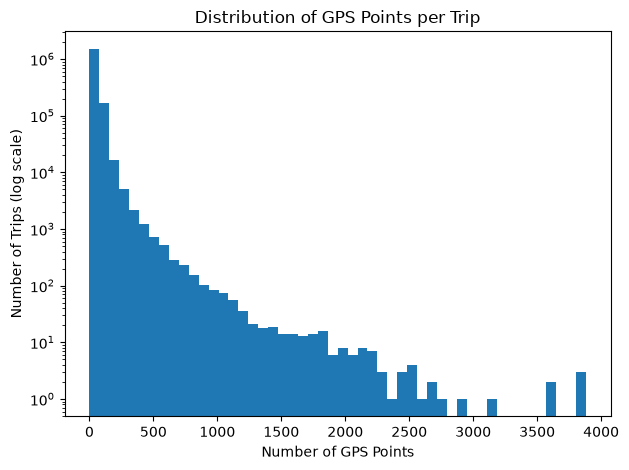

In [20]:
ax = df["GPS_POINTS"].plot(
    kind="hist",
    bins=50,
    title="Distribution of GPS Points per Trip",
    xlabel="Number of GPS Points"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig("../src/results/gps_points_distribution.png", bbox_inches="tight")
plt.show()

## 7. Distribution of Duration per Trip

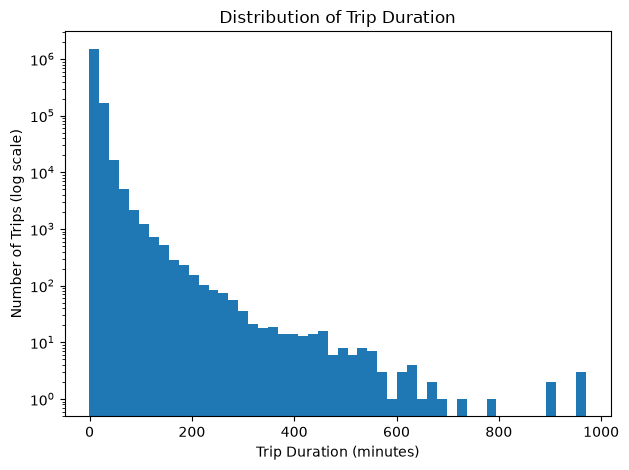

In [21]:
ax = (df["DURATION"] / 60).plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Duration",
    xlabel="Trip Duration (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig("../src/results/duration_distribution.png", bbox_inches="tight")
plt.show()

## 8. Top 10 Most Active Taxi Drivers

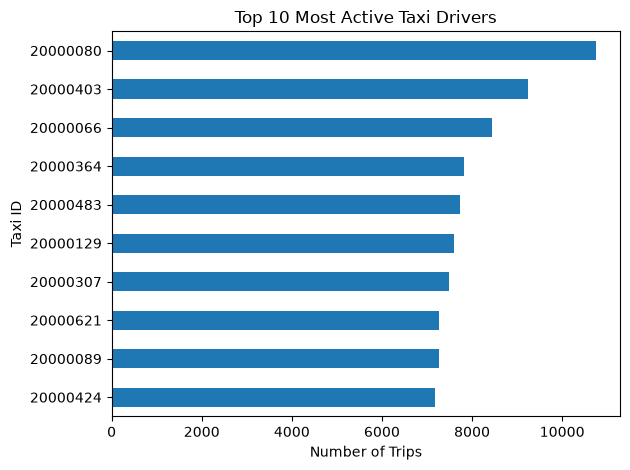

In [22]:
top_taxis = df["TAXI_ID"].value_counts().head(10)

top_taxis.sort_values().plot(
    kind="barh",
    title="Top 10 Most Active Taxi Drivers",
    xlabel="Number of Trips",
    ylabel="Taxi ID"
)
plt.tight_layout()
plt.savefig("../src/results/most_active_taxi_drivers.png", bbox_inches="tight")
plt.show()

## 9. Number of Trips per Taxi

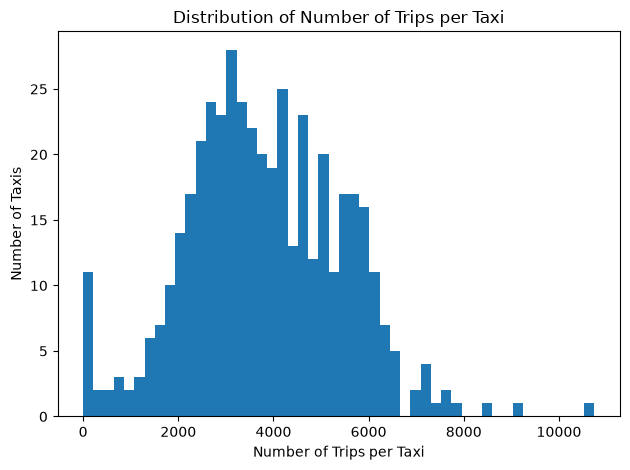

In [23]:
trips_per_taxi = df.groupby("TAXI_ID").size()

trips_per_taxi.plot(
    kind="hist",
    bins=50,
    title="Distribution of Number of Trips per Taxi",
    xlabel="Number of Trips per Taxi",
    ylabel="Number of Taxis"
)
plt.tight_layout()
plt.savefig("../src/results/number_of_trips_per_taxi.png", bbox_inches="tight")
plt.show()

## 10. Heatmaps

### 10.1 Pickup and Drop-off Location Heatmap

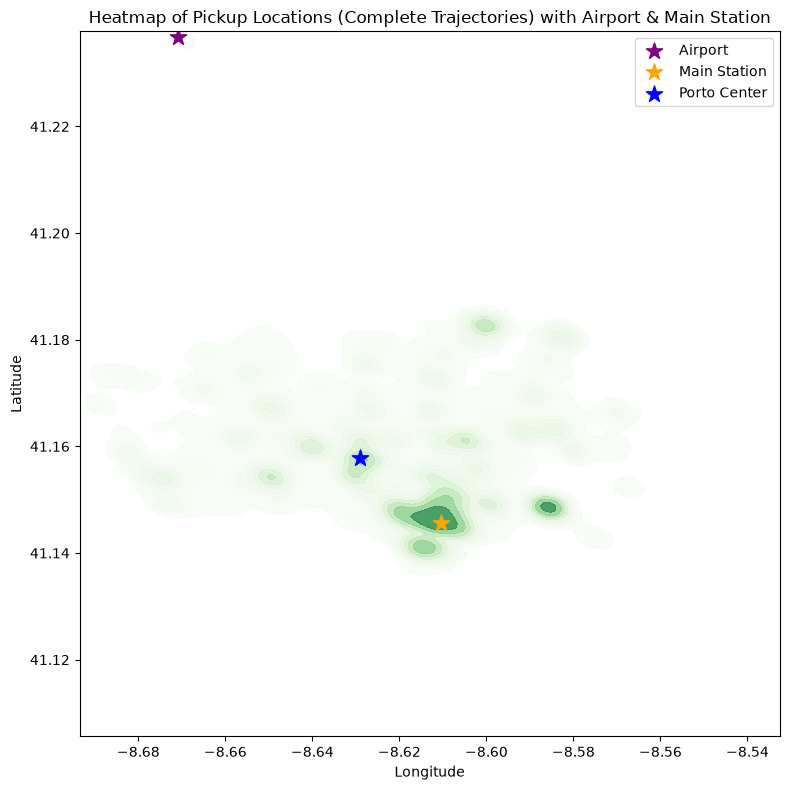

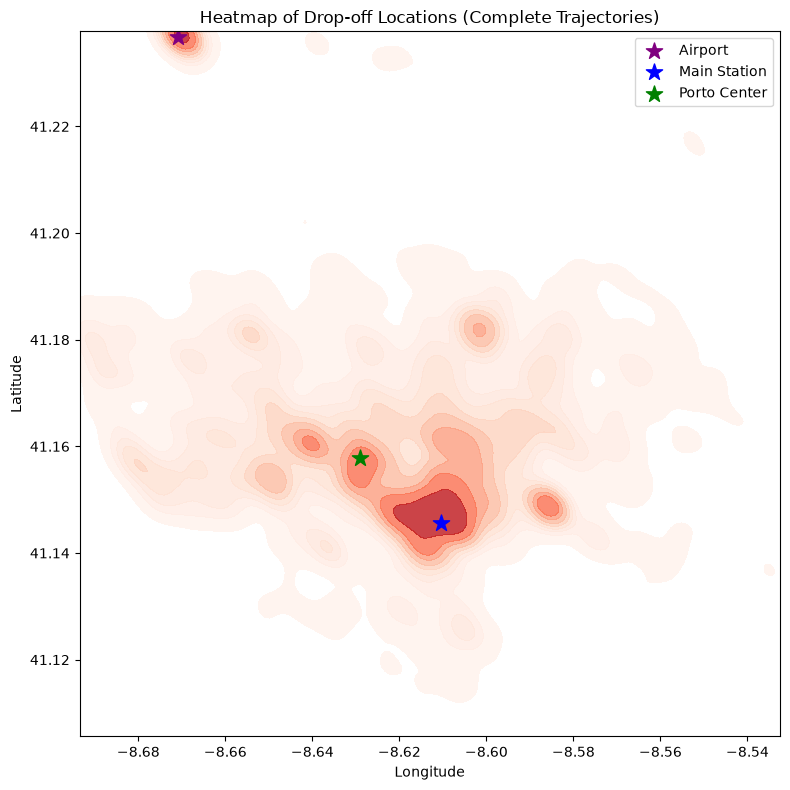

In [43]:
sample_df = df[df["MISSING_DATA"] == False].sample(SUBSET_SIZE, random_state=42)

start_points = []
end_points = []
for polyline in sample_df["POLYLINE"]:
    if polyline:
        start_points.append(polyline[0])
        end_points.append(polyline[-1])
lons_start = np.array([pt[0] for pt in start_points])
lats_start = np.array([pt[1] for pt in start_points])
lons_end = np.array([pt[0] for pt in end_points])
lats_end = np.array([pt[1] for pt in end_points])

min_lon, max_lon = np.percentile(np.concatenate([lons_start, lons_end]), 0.5), np.percentile(np.concatenate([lons_start, lons_end]), 99.5)
min_lat, max_lat = np.percentile(np.concatenate([lats_start, lats_end]), 0.5), np.percentile(np.concatenate([lats_start, lats_end]), 99.5)

pickup_mask = (min_lon <= lons_start) & (lons_start <= max_lon) & (min_lat <= lats_start) & (lats_start <= max_lat)
dropoff_mask = (min_lon <= lons_end) & (lons_end <= max_lon) & (min_lat <= lats_end) & (lats_end <= max_lat)

plt.figure(figsize=(8, 8))
sns.kdeplot(
    x=lons_start[pickup_mask], y=lats_start[pickup_mask], cmap="Greens", fill=True, bw_adjust=0.5, alpha=0.8,
    clip=((min_lon, max_lon), (min_lat, max_lat)),
    label="Pickup"
)
plt.scatter(AIRPORT[0], AIRPORT[1], color="purple", s=150, marker="*", label="Airport")
plt.scatter(MAIN_STATION[0], MAIN_STATION[1], color="orange", s=150, marker="*", label="Main Station")
plt.scatter(PORTO_CENTER[0], PORTO_CENTER[1], color="blue", s=150, marker="*", label="Porto Center")
plt.title("Heatmap of Pickup Locations (Complete Trajectories) with Airport & Main Station")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.savefig("../src/results/pickup_locations_heatmap.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 8))
sns.kdeplot(
    x=lons_end[dropoff_mask], y=lats_end[dropoff_mask], cmap="Reds", fill=True, bw_adjust=0.5, alpha=0.8,
    clip=((min_lon, max_lon), (min_lat, max_lat)), label="Drop-off")
plt.scatter(AIRPORT[0], AIRPORT[1], color="purple", s=150, marker="*", label="Airport")
plt.scatter(MAIN_STATION[0], MAIN_STATION[1], color="blue", s=150, marker="*", label="Main Station")
plt.scatter(PORTO_CENTER[0], PORTO_CENTER[1], color="green", s=150, marker="*", label="Porto Center")
plt.title("Heatmap of Drop-off Locations (Complete Trajectories)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.savefig("../src/results/dropoff_locations_heatmap.png", bbox_inches="tight")
plt.show()

### 10.2 Heatmap of Taxi Trajectories

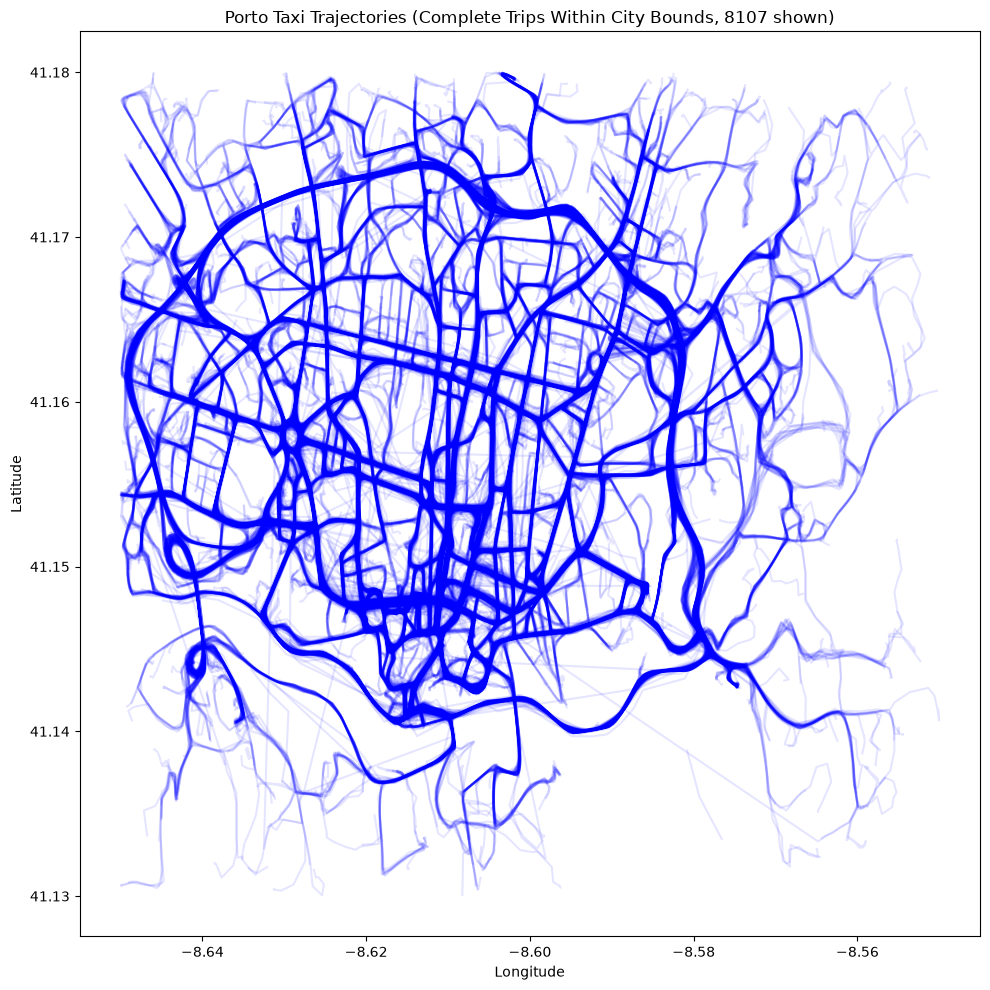

945 trips with jumps within city bounds (out of 15000)


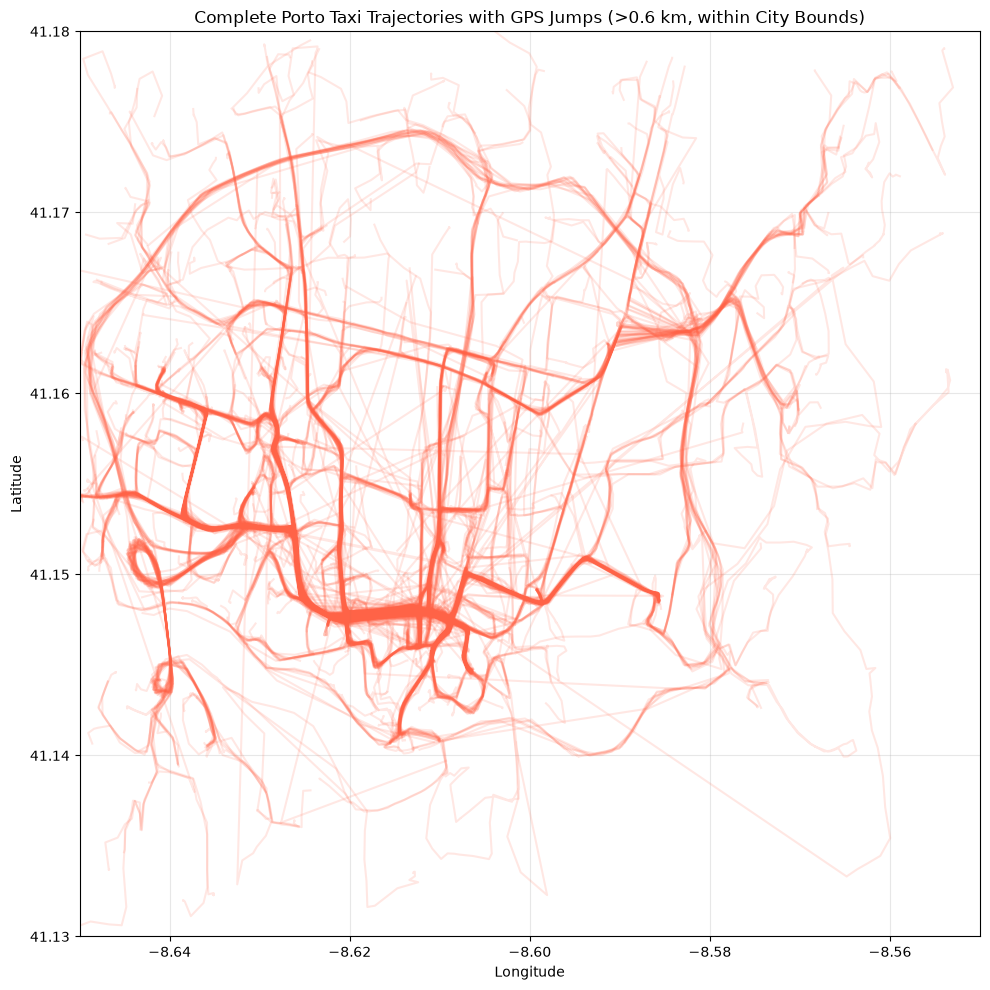

In [46]:
plt.figure(figsize=(10, 10))
count = 0

subset_df = df[df["MISSING_DATA"] == False].sample(SUBSET_SIZE, random_state=42).copy()

# Plot complete trips within city center bounds
for polyline in subset_df["POLYLINE"]:
    if polyline:
        lons, lats = zip(*polyline)
        if is_within_city_bounds(polyline):
            plt.plot(lons, lats, alpha=0.1, color="blue")
            count += 1
plt.title(f"Porto Taxi Trajectories (Complete Trips Within City Bounds, {count} shown)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig("../src/results/complete_taxi_trajectories.png", bbox_inches="tight")
plt.show()

# Inspect unusually large jumps in complete trips within city bounds
subset_df["HAS_JUMP"] = subset_df["POLYLINE"].apply(lambda x: has_large_jump(x, max_jump_km=0.6))
subset_df["WITHIN_CITY"] = subset_df["POLYLINE"].apply(is_within_city_bounds)

jump_city_df = subset_df[(subset_df["HAS_JUMP"]) & (subset_df["WITHIN_CITY"])].copy()

print(f"{len(jump_city_df)} trips with jumps within city bounds (out of {len(subset_df)})")

plt.figure(figsize=(10, 10))
for coords in jump_city_df["POLYLINE"]:
    if coords:
        lons, lats = zip(*coords)
        plt.plot(lons, lats, alpha=0.15, color="tomato")

plt.title("Complete Porto Taxi Trajectories with GPS Jumps (>0.6 km, within City Bounds)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(CITY_BOUNDS[0], CITY_BOUNDS[1])
plt.ylim(CITY_BOUNDS[2], CITY_BOUNDS[3])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../src/results/gps_jumps_trajectories.png", bbox_inches="tight")
plt.show()

## 11. Data Quality

### 11.1 Missing Values

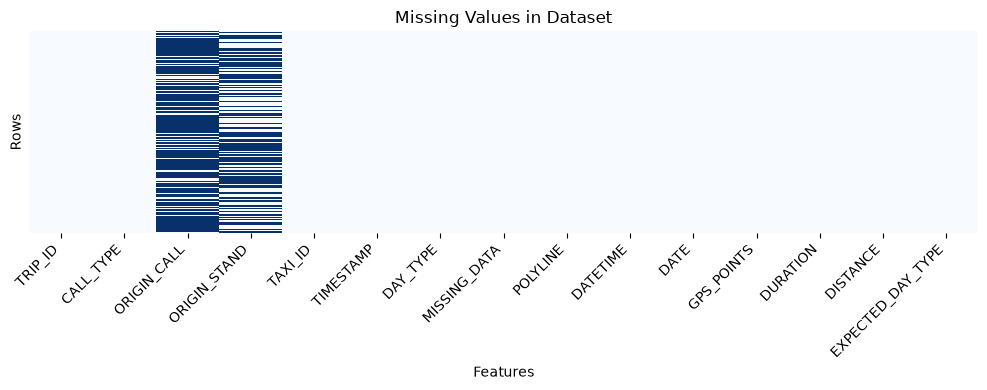

In [41]:
plt.figure(figsize=(10, 4))

ax = sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="Blues",
    yticklabels=False
)

ax.set_title("Missing Values in Dataset")
ax.set_xlabel("Features")
ax.set_ylabel("Rows")

plt.xticks(rotation=45, ha="right")
plt.grid(False)
plt.tight_layout()

plt.savefig(
    "../src/results/missing_values_heatmap.png",
    bbox_inches="tight"
)

plt.show()

### 11.2 Duplicate Values

In [28]:
trip_id_duplicate_mask = df["TRIP_ID"].duplicated(keep=False)
trip_id_duplicate_values = df.loc[trip_id_duplicate_mask, "TRIP_ID"].nunique()
trip_id_duplicate_rows = trip_id_duplicate_mask.sum()
trip_id_extra_rows = df["TRIP_ID"].duplicated().sum()

duplicate_check_df = df.copy()
duplicate_check_df["POLYLINE"] = duplicate_check_df["POLYLINE"].apply(
	lambda polyline: tuple(tuple(point) for point in polyline)
)

exact_duplicate_mask = duplicate_check_df.duplicated(keep=False)
exact_duplicate_values = duplicate_check_df.loc[exact_duplicate_mask].drop_duplicates().shape[0]
exact_duplicate_rows = exact_duplicate_mask.sum()
exact_duplicate_extra_rows = duplicate_check_df.duplicated().sum()

print(f"TRIP_ID values appearing more than once: {trip_id_duplicate_values}")
print(f"Rows belonging to duplicated TRIP_ID values: {trip_id_duplicate_rows}")
print(f"Extra rows caused by duplicated TRIP_ID values: {trip_id_extra_rows}")
print(f"Exact duplicate trip groups: {exact_duplicate_values}")
print(f"Rows belonging to exact duplicate groups: {exact_duplicate_rows}")
print(f"Extra rows caused by exact duplicates: {exact_duplicate_extra_rows}")

TRIP_ID values appearing more than once: 80
Rows belonging to duplicated TRIP_ID values: 161
Extra rows caused by duplicated TRIP_ID values: 81
Exact duplicate trip groups: 3
Rows belonging to exact duplicate groups: 6
Extra rows caused by exact duplicates: 3


In [37]:
missing_by_taxi = (
    df.groupby("TAXI_ID")
    .agg(
        total_trips=("TRIP_ID", "size"),
        missing_trips=("MISSING_DATA", "sum")
    )
    .assign(fraction_missing=lambda data: data["missing_trips"] / data["total_trips"])
    .query("missing_trips > 0")
    .sort_values("fraction_missing", ascending=False)
    .reset_index()
)

display(missing_by_taxi)

,TAXI_ID,total_trips,missing_trips,fraction_missing
0,20000640,5899,2,0.000339
1,20000508,3381,1,0.000296
2,20000163,3483,1,0.000287
3,20000387,3992,1,0.000251
4,20000454,4714,1,0.000212
5,20000904,5037,1,0.000199
6,20000057,5620,1,0.000178
7,20000625,5869,1,0.000170
8,20000678,6538,1,0.000153


### 11.3 Inconsistent Values

In [29]:
print(
    ((df["CALL_TYPE"] == "A") & df["ORIGIN_CALL"].isna()).sum(),
    "A trips have missing ORIGIN_CALL"
)

print(
    ((df["CALL_TYPE"] != "A") & df["ORIGIN_CALL"].notna()).sum(),
    "non-A trips incorrectly have ORIGIN_CALL"
)

print(
    ((df["CALL_TYPE"] == "B") & df["ORIGIN_STAND"].isna()).sum(),
    "B trips have missing ORIGIN_STAND"
)

print(
    ((df["CALL_TYPE"] != "B") & df["ORIGIN_STAND"].notna()).sum(),
    "non-B trips incorrectly have ORIGIN_STAND"
)

0 A trips have missing ORIGIN_CALL
0 non-A trips incorrectly have ORIGIN_CALL
11302 B trips have missing ORIGIN_STAND
0 non-B trips incorrectly have ORIGIN_STAND


0 out of 1625911 Normal days are incorrectly marked
40671 out of 40671 Holidays are incorrectly marked
44088 out of 44088 Days before holidays are incorrectly marked

84759 out of 1710670 trips marked A should have a different DAY_TYPE
0 out of 0 trips marked B should have a different DAY_TYPE
0 out of 0 trips marked C should have a different DAY_TYPE


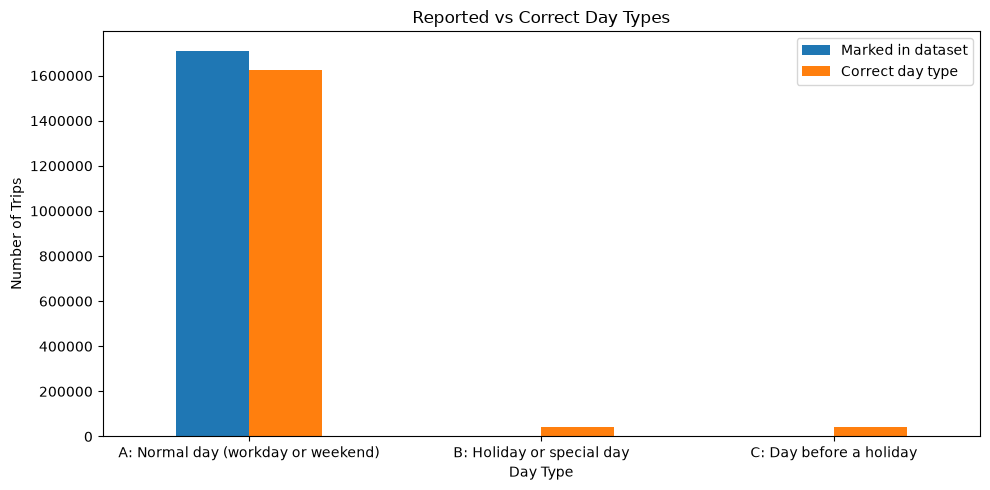

In [40]:
years = pd.to_datetime(df["DATE"]).dt.year.unique()

pt_holidays = holidays.Portugal(years=years)

holiday_dates = set(pt_holidays.keys())

day_before_holiday = {
    day - pd.Timedelta(days=1)
    for day in holiday_dates
}
df["EXPECTED_DAY_TYPE"] = df["DATE"].apply(get_correct_day_type, args=(holiday_dates, day_before_holiday))

day_type_names = {
    "A": "Normal days",
    "B": "Holidays",
    "C": "Days before holidays"
}

for day_type in ["A", "B", "C"]:

    df_expected = df[df["EXPECTED_DAY_TYPE"] == day_type]

    incorrect = (df_expected["DAY_TYPE"] != day_type).sum()

    print(
        incorrect,
        "out of",
        len(df_expected),
        f"{day_type_names[day_type]} are incorrectly marked"
    )

print()

for day_type in ["A", "B", "C"]:

    df_marked = df[df["DAY_TYPE"] == day_type]

    incorrect = (df_marked["EXPECTED_DAY_TYPE"] != day_type).sum()

    print(
        incorrect,
        "out of",
        len(df_marked),
        f"trips marked {day_type} should have a different DAY_TYPE"
    )

marked_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

correct_counts = (
    df["EXPECTED_DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

comparison = pd.DataFrame({
    "Marked in dataset": marked_counts,
    "Correct day type": correct_counts
})

comparison.index = comparison.index.map({
    "A": "A: Normal day (workday or weekend)",
    "B": "B: Holiday or special day",
    "C": "C: Day before a holiday"
})

ax = comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Reported vs Correct Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig(
    "../src/results/day_type_validation.png",
    bbox_inches="tight"
)
plt.show()

10 rows are marked as missing data
0 rows have empty POLYLINE, aka no location data
10 rows are missing location data
The missing rows make up 0.00% of the dataset
0 rows have both MISSING_DATA == True and empty POLYLINE


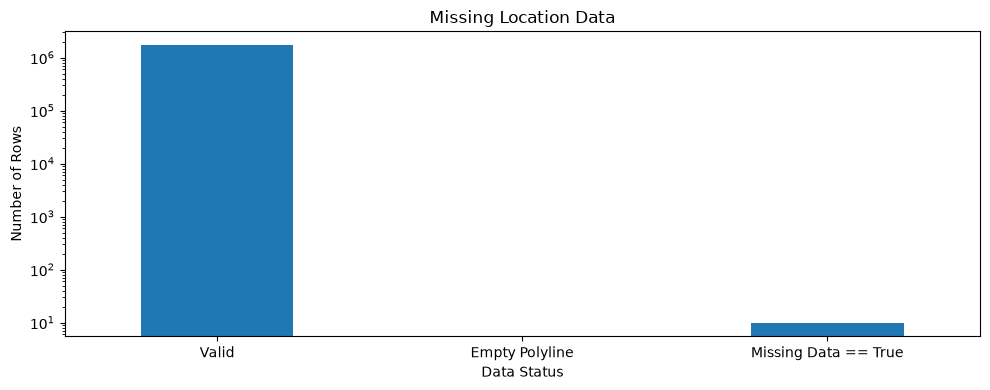

In [49]:
missing_data_marked = df[df["MISSING_DATA"] == True]
empty_polyline = df[df["POLYLINE"] == "[]"]

both = df[
    (df["MISSING_DATA"] == True) &
    (df["POLYLINE"] == "[]")
]

missing_data_all = (
    len(missing_data_marked)
    + len(empty_polyline)
    - len(both)
)

print(len(missing_data_marked), "rows are marked as missing data")
print(len(empty_polyline), "rows have empty POLYLINE, aka no location data")
print(missing_data_all, "rows are missing location data")
print(f"The missing rows make up {missing_data_all / len(df) * 100:.2f}% of the dataset")
print(len(both), "rows have both MISSING_DATA == True and empty POLYLINE")

labels = ["Valid", "Empty Polyline", "Missing Data == True"]

numbers = [
    len(df) - missing_data_all,
    len(empty_polyline),
    len(missing_data_marked)
]

missing_location_data = pd.Series(numbers, index=labels)

ax = missing_location_data.plot(
    kind="bar",
    figsize=(10, 4),
    title="Missing Location Data",
    xlabel="Data Status",
    ylabel="Number of Rows",
    logy=True,
    rot=0
)

ax.grid(False)

plt.tight_layout()
plt.savefig(
    "../src/results/missing_location_data.png",
    bbox_inches="tight"
)
plt.show()